# Phase 7: Regime-Wise Model Evaluation

## Objective

Evaluate industrial energy forecasting models separately across
Normal, High, and Peak operating regimes.

Forecast horizons:
- 15 minutes ahead: target_15min
- 1 hour ahead: target_1hour

Metrics:
- MAE
- RMSE
- R²
- Peak Recall
- Inference latency
- Model complexity

The current energy regime determines the evaluation group.
Future actual consumption is used only to evaluate forecast accuracy
and identify future peak events, never to select the current regime.

The chronological test set remains untouched during model selection.

## imports and paths

In [22]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("../Data/processed")
RESULTS_DIR = DATA_DIR / "phase7_results"

DATA_PATH = DATA_DIR / "steel_industry_model_ready.csv"
REGIME_PATH = DATA_DIR / "steel_industry_regimes.csv"
THRESHOLD_PATH = DATA_DIR / "phase6_regime_thresholds.json"
CONFIG_PATH = DATA_DIR / "feature_config.json"

RANDOM_STATE = 42
PURGE_GAP = 4

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Phase 7 paths initialized.")

Phase 7 paths initialized.


## load datasets and configuration

In [23]:
required_paths = [
    DATA_PATH,
    REGIME_PATH,
    THRESHOLD_PATH,
    CONFIG_PATH
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path.resolve()}"
        )

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
regimes_df = pd.read_csv(
    REGIME_PATH,
    parse_dates=["timestamp"]
)

with open(THRESHOLD_PATH, "r", encoding="utf-8") as f:
    thresholds = json.load(f)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    feature_config = json.load(f)

features_A = feature_config["X_A"]
features_B = feature_config["X_B"]
features_C = feature_config["X_C"]

feature_sets = {
    "X_A": features_A,
    "X_B": features_B,
    "X_C": features_C
}

targets = ["target_15min", "target_1hour"]

p75 = float(thresholds["p75_kwh"])
p90 = float(thresholds["p90_kwh"])

print("Model-ready dataset:", df.shape)
print("Regime-labelled dataset:", regimes_df.shape)
print(f"P75 = {p75:.3f} kWh")
print(f"P90 = {p90:.3f} kWh")

Model-ready dataset: (34940, 28)
Regime-labelled dataset: (34940, 29)
P75 = 51.340 kWh
P90 = 81.049 kWh


## validate and recreate the Phase 5 split

In [24]:
df = df.sort_values("timestamp").reset_index(drop=True)
regimes_df = (
    regimes_df.sort_values("timestamp")
    .reset_index(drop=True)
)

assert df["timestamp"].is_unique
assert df["timestamp"].is_monotonic_increasing
assert regimes_df["timestamp"].is_unique

# Ensure the regime labels correspond to the model-ready observations.
assert df["timestamp"].equals(regimes_df["timestamp"])
assert np.allclose(
    df["Usage_kWh"].to_numpy(),
    regimes_df["Usage_kWh"].to_numpy()
)

split_index = int(len(df) * 0.80)
train_end = split_index - PURGE_GAP

train_df = df.iloc[:train_end].copy()
test_df = df.iloc[split_index:].copy()

test_regimes = regimes_df.iloc[split_index:].copy()

assert len(train_df) == 27948
assert len(test_df) == 6988
assert len(df.iloc[train_end:split_index]) == PURGE_GAP

assert (
    train_df["timestamp"].max()
    < test_df["timestamp"].min()
)

assert (
    test_df["timestamp"].reset_index(drop=True)
    .equals(test_regimes["timestamp"].reset_index(drop=True))
)

print("Training observations:", len(train_df))
print("Purged observations:", PURGE_GAP)
print("Test observations:", len(test_df))
print("Test start:", test_df["timestamp"].min())

Training observations: 27948
Purged observations: 4
Test observations: 6988
Test start: 2018-10-20 04:00:00


## Evaluation Metrics

### Forecast error

MAE and RMSE are calculated separately for each current operating regime.

R² is reported where it is mathematically defined, but should be interpreted
cautiously for small or low-variance subsets.

### Peak Recall

A future peak event occurs when the actual target energy consumption is
greater than or equal to the Phase 6 training-derived P90 threshold.

A predicted peak occurs when the predicted target is greater than or equal
to that same threshold.

Peak Recall = True Positives / (True Positives + False Negatives)

This evaluates whether the model detects future high-demand events.
The current regime and future peak event are separate variables.

### Inference latency

Measure prediction time on the held-out test features and report average
milliseconds per observation. This is a benchmark on the current machine,
not a guarantee of production latency.

### Model complexity

Record a consistent proxy, such as serialized model size in bytes.
This does not fully represent computational or conceptual complexity.

## 3. Define Forecasting Models

Evaluate the six regression models used in Phase 5 across feature sets X_A, X_B, and X_C.

Use identical chronological test observations for each comparison.

X_C remains a conditional benchmark because current sensor availability at forecast time must be established.

In [25]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def build_models():
    return {
        "Linear Regression": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=16,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        ),

        "LightGBM": LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=8,
            num_leaves=31,
            min_child_samples=30,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor(
                n_neighbors=7,
                weights="distance",
                n_jobs=-1
            ))
        ]),

        "SVR": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR(
                kernel="rbf",
                C=10,
                epsilon=0.5
            ))
        ])
    }

models = build_models()
print("Models:", list(models.keys()))

Models: ['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'KNN', 'SVR']


## 4. Prepare Current Operating Regimes

Use the regime labels already calculated in Phase 6.

The regime at time t is used to group forecasts issued at time t.
Future actual consumption is used only for calculating forecast errors
and identifying future peak events.

In [26]:
regime_column = "Energy_Regime"

assert regime_column in test_regimes.columns

regime_order = ["Normal", "High", "Peak"]

test_regimes = test_regimes.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

assert test_df["timestamp"].equals(test_regimes["timestamp"])

test_regime_labels = test_regimes[regime_column].astype(str)

print("Test regime distribution:")
display(
    test_regime_labels
    .value_counts()
    .reindex(regime_order, fill_value=0)
    .rename("count")
    .to_frame()
)

Test regime distribution:


,count
Energy_Regime,
Normal,5248
High,1295
Peak,445


## 5. Define Evaluation Metrics

For each model, feature set, forecast horizon, and current regime, calculate:

- MAE
- RMSE
- R², when defined
- Mean inference latency in milliseconds per observation

Peak Recall is calculated separately for future peak events, defined as
actual target consumption greater than or equal to the training-derived P90 threshold.

## metric helper

In [27]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def calculate_regime_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    result = {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

    # R² is undefined when fewer than two observations are present
    # or when actual values have zero variance.
    if len(y_true) >= 2 and np.var(y_true) > 0:
        result["R2"] = r2_score(y_true, y_pred)
    else:
        result["R2"] = np.nan

    return result

## generate test predictions

In [28]:
prediction_records = []
regime_metric_records = []
latency_records = []

for feature_name, feature_cols in feature_sets.items():

    X_train = train_df[feature_cols]
    X_test = test_df[feature_cols]

    for target in targets:

        y_train = train_df[target]
        y_test = test_df[target]

        for model_name, base_model in build_models().items():

            print(
                f"Training {model_name} | "
                f"{feature_name} | {target}"
            )

            model = clone(base_model)
            model.fit(X_train, y_train)

            # Warm-up prediction, excluded from latency measurement.
            model.predict(X_test.iloc[:min(10, len(X_test))])

            start_time = time.perf_counter()
            y_pred = model.predict(X_test)
            elapsed = time.perf_counter() - start_time

            latency_ms = elapsed * 1000 / len(X_test)

            model_key = (model_name, feature_name, target)

            for i in range(len(test_df)):
                prediction_records.append({
                    "timestamp": test_df.loc[i, "timestamp"],
                    "Model": model_name,
                    "Feature_Set": feature_name,
                    "Target": target,
                    "Current_Regime": test_regime_labels.iloc[i],
                    "Actual": float(y_test.iloc[i]),
                    "Predicted": float(y_pred[i])
                })

            latency_records.append({
                "Model": model_name,
                "Feature_Set": feature_name,
                "Target": target,
                "Latency_ms_per_observation": latency_ms,
                "Test_observations": len(X_test)
            })

            # Calculate errors separately for each current regime.
            for regime in regime_order:
                mask = (
                    test_regime_labels.to_numpy() == regime
                )

                if mask.sum() == 0:
                    continue

                metrics = calculate_regime_metrics(
                    y_test.to_numpy()[mask],
                    np.asarray(y_pred)[mask]
                )

                regime_metric_records.append({
                    "Model": model_name,
                    "Feature_Set": feature_name,
                    "Target": target,
                    "Current_Regime": regime,
                    "N": int(mask.sum()),
                    **metrics
                })

predictions_df = pd.DataFrame(prediction_records)
regime_metrics = pd.DataFrame(regime_metric_records)
latency_df = pd.DataFrame(latency_records)

print("Prediction rows:", len(predictions_df))
print("Regime metric rows:", len(regime_metrics))
print("Latency records:", len(latency_df))

Training Linear Regression | X_A | target_15min
Training Random Forest | X_A | target_15min
Training XGBoost | X_A | target_15min
Training LightGBM | X_A | target_15min
Training KNN | X_A | target_15min
Training SVR | X_A | target_15min
Training Linear Regression | X_A | target_1hour
Training Random Forest | X_A | target_1hour
Training XGBoost | X_A | target_1hour
Training LightGBM | X_A | target_1hour
Training KNN | X_A | target_1hour
Training SVR | X_A | target_1hour
Training Linear Regression | X_B | target_15min
Training Random Forest | X_B | target_15min
Training XGBoost | X_B | target_15min
Training LightGBM | X_B | target_15min
Training KNN | X_B | target_15min
Training SVR | X_B | target_15min
Training Linear Regression | X_B | target_1hour
Training Random Forest | X_B | target_1hour
Training XGBoost | X_B | target_1hour
Training LightGBM | X_B | target_1hour
Training KNN | X_B | target_1hour
Training SVR | X_B | target_1hour
Training Linear Regression | X_C | target_15min
Trai

## 6. Model Complexity Assessment

Measure model complexity using serialized model size in bytes.

This provides a consistent, measurable proxy for deployment footprint.
It does not capture all aspects of complexity, such as inference cost,
training time, interpretability, or memory use during execution.

Model size is measured for each fitted model and feature-set combination.

In [29]:
import pickle

complexity_records = []

for (model_name, feature_name, target), group in predictions_df.groupby(
    ["Model", "Feature_Set", "Target"]
):
    # Refit on the established training period to measure the same
    # model configuration used in the evaluation workflow.
    feature_cols = feature_sets[feature_name]

    model = clone(build_models()[model_name])
    model.fit(train_df[feature_cols], train_df[target])

    serialized_size_bytes = len(
        pickle.dumps(model, protocol=pickle.HIGHEST_PROTOCOL)
    )

    complexity_records.append({
        "Model": model_name,
        "Feature_Set": feature_name,
        "Target": target,
        "Model_Size_Bytes": serialized_size_bytes,
        "Model_Size_KB": serialized_size_bytes / 1024
    })

complexity_df = pd.DataFrame(complexity_records)

display(
    complexity_df.sort_values("Model_Size_KB").round(3)
)

,Model,Feature_Set,Target,Model_Size_Bytes,Model_Size_KB
12,Linear Regression,X_A,target_15min,761,0.743
13,Linear Regression,X_A,target_1hour,761,0.743
14,Linear Regression,X_B,target_15min,989,0.966
15,Linear Regression,X_B,target_1hour,989,0.966
17,Linear Regression,X_C,target_1hour,1193,1.165
16,Linear Regression,X_C,target_15min,1193,1.165
33,XGBoost,X_B,target_1hour,818425,799.243
31,XGBoost,X_A,target_1hour,821951,802.687
30,XGBoost,X_A,target_15min,822223,802.952
34,XGBoost,X_C,target_15min,822529,803.251


## save complexity results

In [30]:
complexity_df.to_csv(
    RESULTS_DIR / "phase7_model_complexity.csv",
    index=False
)

print(
    "Saved model complexity results to:",
    (RESULTS_DIR / "phase7_model_complexity.csv").resolve()
)

Saved model complexity results to: D:\Research Paper Codes\Data\processed\phase7_results\phase7_model_complexity.csv


## 6. Evaluate Future Peak Detection

A future peak event occurs when the actual forecast target is greater than
or equal to the P90 threshold calculated from training data.

A predicted peak occurs when the model's forecast is greater than or equal
to that same threshold.

Peak Recall = True Positives / (True Positives + False Negatives).

Report Peak Recall for each current operating regime and forecast horizon.
This measures whether a model detects future peak consumption events.

## calculate Peak Recall

In [31]:
peak_recall_records = []

for (model_name, feature_name, target), group in predictions_df.groupby(
    ["Model", "Feature_Set", "Target"]
):

    actual_peak = group["Actual"].to_numpy() >= p90
    predicted_peak = group["Predicted"].to_numpy() >= p90

    for regime in regime_order:

        regime_mask = (
            group["Current_Regime"].to_numpy() == regime
        )

        true_positive = int(
            np.sum(
                actual_peak[regime_mask]
                & predicted_peak[regime_mask]
            )
        )

        false_negative = int(
            np.sum(
                actual_peak[regime_mask]
                & ~predicted_peak[regime_mask]
            )
        )

        actual_peak_count = true_positive + false_negative

        recall = (
            true_positive / actual_peak_count
            if actual_peak_count > 0
            else np.nan
        )

        peak_recall_records.append({
            "Model": model_name,
            "Feature_Set": feature_name,
            "Target": target,
            "Current_Regime": regime,
            "Actual_Future_Peaks": actual_peak_count,
            "True_Positives": true_positive,
            "False_Negatives": false_negative,
            "Peak_Recall": recall
        })

peak_recall_df = pd.DataFrame(peak_recall_records)

display(
    peak_recall_df[
        peak_recall_df["Current_Regime"] == "Peak"
    ].head(18)
)

,Model,Feature_Set,Target,Current_Regime,Actual_Future_Peaks,True_Positives,False_Negatives,Peak_Recall
2,KNN,X_A,target_15min,Peak,309,142,167,0.459547
5,KNN,X_A,target_1hour,Peak,197,26,171,0.131980
8,KNN,X_B,target_15min,Peak,309,163,146,0.527508
11,KNN,X_B,target_1hour,Peak,197,32,165,0.162437
14,KNN,X_C,target_15min,Peak,309,202,107,0.653722
17,KNN,X_C,target_1hour,Peak,197,41,156,0.208122
20,LightGBM,X_A,target_15min,Peak,309,234,75,0.757282
23,LightGBM,X_A,target_1hour,Peak,197,105,92,0.532995
26,LightGBM,X_B,target_15min,Peak,309,245,64,0.792880
29,LightGBM,X_B,target_1hour,Peak,197,121,76,0.614213


## combine evaluation metrics

In [32]:
evaluation_results = regime_metrics.merge(
    latency_df,
    on=["Model", "Feature_Set", "Target"],
    how="left"
)

evaluation_results = evaluation_results.merge(
    peak_recall_df,
    on=["Model", "Feature_Set", "Target", "Current_Regime"],
    how="left"
)

evaluation_results = evaluation_results.merge(
    complexity_df,
    on=["Model", "Feature_Set", "Target"],
    how="left",
    validate="many_to_one"
)

evaluation_results = evaluation_results.sort_values(
    ["Target", "Current_Regime", "MAE"]
).reset_index(drop=True)

display(evaluation_results.round(4))

,Model,Feature_Set,Target,Current_Regime,N,MAE,RMSE,R2,Latency_ms_per_observation,Test_observations,Actual_Future_Peaks,True_Positives,False_Negatives,Peak_Recall,Model_Size_Bytes,Model_Size_KB
0,LightGBM,X_C,target_15min,High,1295,9.1131,12.6498,0.4524,0.0045,6988,112,38,74,0.3393,825389,806.0439
1,XGBoost,X_C,target_15min,High,1295,9.1390,12.6916,0.4487,0.0016,6988,112,33,79,0.2946,822529,803.2510
2,LightGBM,X_A,target_15min,High,1295,9.7505,13.8871,0.3400,0.0051,6988,112,37,75,0.3304,832191,812.6865
3,XGBoost,X_A,target_15min,High,1295,9.8428,13.9880,0.3304,0.0011,6988,112,34,78,0.3036,822223,802.9521
4,XGBoost,X_B,target_15min,High,1295,9.8844,13.9950,0.3297,0.0012,6988,112,39,73,0.3482,824205,804.8877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,KNN,X_B,target_1hour,Peak,445,32.8191,39.8025,-0.0620,0.0889,6988,197,32,165,0.1624,3361397,3282.6143
104,KNN,X_A,target_1hour,Peak,445,33.1686,39.9606,-0.0705,0.0420,6988,197,26,171,0.1320,2401329,2345.0479
105,SVR,X_A,target_1hour,Peak,445,33.6706,40.3860,-0.0934,1.4060,6988,197,3,194,0.0152,1461262,1427.0137
106,Linear Regression,X_B,target_1hour,Peak,445,33.7731,40.5111,-0.1002,0.0005,6988,197,28,169,0.1421,989,0.9658


## 7. Identify Best Models by Regime

For each forecast horizon and current operating regime, rank models by MAE.

This is a descriptive comparison. Do not use the held-out test results to tune models or repeatedly revise model settings.

The resulting table will inform the later TOPSIS decision framework, which will combine accuracy and operational criteria.

## best model per regime

In [33]:
best_by_regime = (
    evaluation_results
    .sort_values("MAE")
    .groupby(
        ["Target", "Current_Regime"],
        as_index=False
    )
    .first()
)

display(
    best_by_regime[
        [
            "Target",
            "Current_Regime",
            "Model",
            "Feature_Set",
            "N",
            "MAE",
            "RMSE",
            "R2",
            "Peak_Recall",
            "Latency_ms_per_observation"
        ]
    ].round(4)
)

,Target,Current_Regime,Model,Feature_Set,N,MAE,RMSE,R2,Peak_Recall,Latency_ms_per_observation
0,target_15min,High,LightGBM,X_C,1295,9.1131,12.6498,0.4524,0.3393,0.0045
1,target_15min,Normal,LightGBM,X_C,5248,2.1966,5.1530,0.9031,0.0417,0.0045
2,target_15min,Peak,XGBoost,X_C,445,16.7802,20.9609,0.3629,0.9320,0.0016
3,target_1hour,High,LightGBM,X_A,1295,11.0933,16.0030,0.6203,0.1525,0.0026
4,target_1hour,Normal,Random Forest,X_C,5248,4.4754,10.5299,0.7974,0.2769,0.0148
5,target_1hour,Peak,Random Forest,X_A,445,19.1381,24.5437,0.5962,0.5736,0.0156


## plot MAE by regime

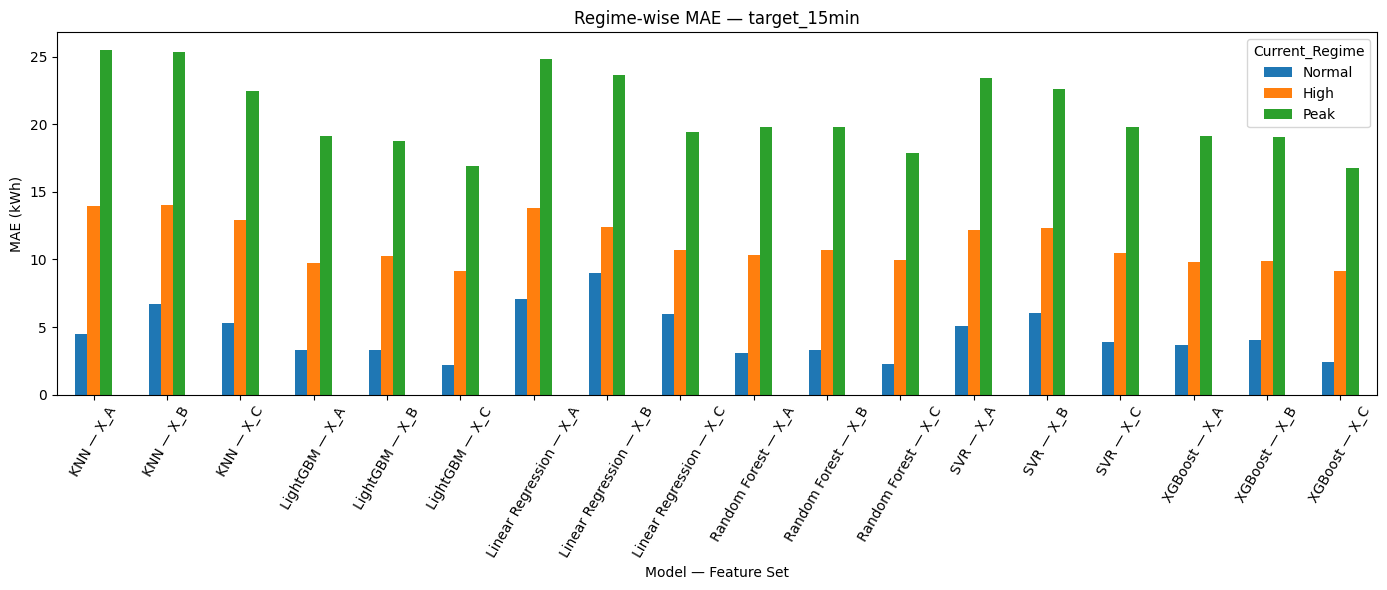

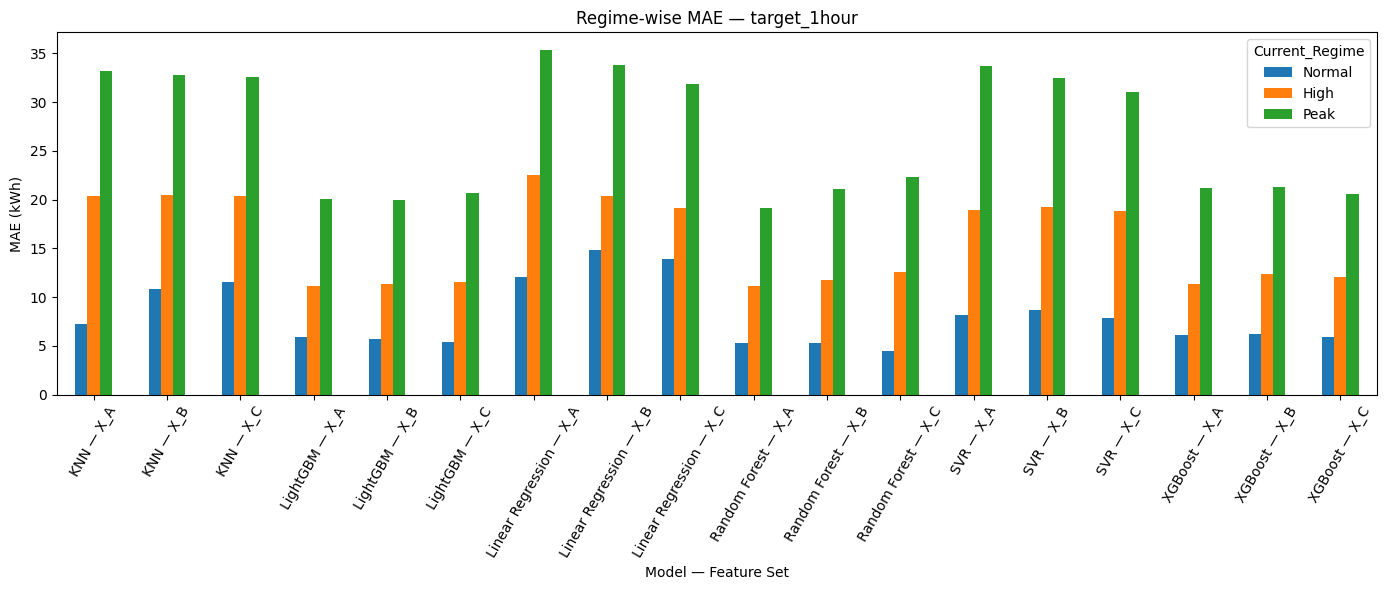

In [34]:
for target in targets:
    subset = evaluation_results[
        evaluation_results["Target"] == target
    ].copy()

    subset["Model_Feature_Set"] = (
        subset["Model"] + " — " + subset["Feature_Set"]
    )

    summary = subset.pivot(
        index="Model_Feature_Set",
        columns="Current_Regime",
        values="MAE"
    ).reindex(columns=regime_order)

    ax = summary.plot(
        kind="bar",
        figsize=(14, 6)
    )

    ax.set_title(f"Regime-wise MAE — {target}")
    ax.set_xlabel("Model — Feature Set")
    ax.set_ylabel("MAE (kWh)")
    ax.tick_params(axis="x", rotation=60)

    plt.tight_layout()
    plt.show()

## save Phase 7 outputs

In [35]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

predictions_df.to_csv(
    RESULTS_DIR / "phase7_test_predictions.csv",
    index=False
)

regime_metrics.to_csv(
    RESULTS_DIR / "phase7_regime_metrics.csv",
    index=False
)

peak_recall_df.to_csv(
    RESULTS_DIR / "phase7_peak_recall.csv",
    index=False
)

latency_df.to_csv(
    RESULTS_DIR / "phase7_latency.csv",
    index=False
)

evaluation_results.to_csv(
    RESULTS_DIR / "phase7_combined_evaluation.csv",
    index=False
)

best_by_regime.to_csv(
    RESULTS_DIR / "phase7_best_by_regime.csv",
    index=False
)

print("Phase 7 outputs saved to:", RESULTS_DIR.resolve())

Phase 7 outputs saved to: D:\Research Paper Codes\Data\processed\phase7_results


## 8. Interpretation and Limitations

### Key Findings

1. Forecasting errors vary across operating regimes. MAE generally increases from Normal to High and Peak conditions, indicating that high-consumption periods are more challenging to forecast.

2. The best-performing model differs by forecast horizon and operating regime. LightGBM performs best for Normal and High regimes at the 15-minute horizon, while XGBoost performs best in the Peak regime. At the 1-hour horizon, Random Forest performs best in the Normal and Peak regimes, while LightGBM performs best in the High regime.

3. Feature-set performance is not uniform. X_C performs best in several regime-horizon combinations, whereas X_A performs best for the High and Peak regimes at the 1-hour horizon. The operational validity of X_C depends on the availability of current sensor readings at forecast time.

4. Peak-event detection must be evaluated separately from regression accuracy. Regime-wise Peak Recall measures detection of future peak events within each current operating regime and should be supplemented with overall Peak Recall, precision, and F1-score.

### Limitations

- **Regime distribution:** The test set contains 445 observations in the Peak regime, compared with 2,795 in training. Peak-regime metrics may therefore be less stable than Normal-regime metrics.

- **Feature availability:** X_C includes current sensor measurements. These features should be considered conditional until their availability at forecast origin is verified.

- **Temporal generalization:** Evaluation uses one chronological holdout period. Performance may differ under other operating conditions or time periods.

- **Latency:** Measured inference latency depends on the computing environment and batch size. It should not be interpreted as a production latency guarantee.

- **Model complexity:** Inference latency alone does not fully capture model complexity, memory requirements, or deployment cost.

- **Model selection:** The best-performing model in each test regime is identified descriptively. Test-set rankings must not be used for further hyperparameter tuning or repeated model selection.

### Implications for Phase 8

The regime-wise results provide evidence that different models may be suitable under different operating conditions. However, the lowest-MAE model is not automatically the best operational choice.

Phase 8 will develop a multi-criteria decision framework using entropy weighting and TOPSIS to rank candidate models using forecast error, peak-event detection, inference latency, and model complexity.

The resulting adaptive policy will subsequently be compared against a static model-selection policy.

## 9. Overall Future-Peak Detection Metrics

Evaluate future-peak event detection across the entire test period for every model, feature set, and forecast horizon.

A future peak event is defined as actual target consumption greater than or equal to the P90 threshold derived from training data.

A predicted peak event is defined as predicted target consumption greater than or equal to the same threshold.

Calculate:
- Precision: proportion of predicted peak events that were actual peaks.
- Recall: proportion of actual peak events detected by the model.
- F1-score: harmonic mean of precision and recall.

These metrics are calculated across the complete test period, not separately by current operating regime.

## calculate overall precision, recall and F1-score

In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

overall_peak_records = []

for (model_name, feature_name, target), group in predictions_df.groupby(
    ["Model", "Feature_Set", "Target"]
):
    actual_peak = (
        group["Actual"].to_numpy() >= p90
    ).astype(int)

    predicted_peak = (
        group["Predicted"].to_numpy() >= p90
    ).astype(int)

    precision = precision_score(
        actual_peak,
        predicted_peak,
        zero_division=0
    )

    recall = recall_score(
        actual_peak,
        predicted_peak,
        zero_division=0
    )

    f1 = f1_score(
        actual_peak,
        predicted_peak,
        zero_division=0
    )

    overall_peak_records.append({
        "Model": model_name,
        "Feature_Set": feature_name,
        "Target": target,
        "Test_Observations": len(group),
        "Actual_Peak_Count": int(actual_peak.sum()),
        "Predicted_Peak_Count": int(predicted_peak.sum()),
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

overall_peak_metrics = pd.DataFrame(overall_peak_records)

overall_peak_metrics = overall_peak_metrics.sort_values(
    ["Target", "Recall"],
    ascending=[True, False]
).reset_index(drop=True)

display(overall_peak_metrics.round(4))

,Model,Feature_Set,Target,Test_Observations,Actual_Peak_Count,Predicted_Peak_Count,Precision,Recall,F1_Score
0,LightGBM,X_C,target_15min,6988,445,439,0.7358,0.7258,0.7308
1,XGBoost,X_C,target_15min,6988,445,440,0.7318,0.7236,0.7277
2,Random Forest,X_C,target_15min,6988,445,459,0.6906,0.7124,0.7013
3,LightGBM,X_B,target_15min,6988,445,422,0.6754,0.6404,0.6574
4,LightGBM,X_A,target_15min,6988,445,380,0.7132,0.6090,0.6570
5,XGBoost,X_A,target_15min,6988,445,384,0.6953,0.6000,0.6441
6,XGBoost,X_B,target_15min,6988,445,380,0.7000,0.5978,0.6448
7,Random Forest,X_B,target_15min,6988,445,369,0.7127,0.5910,0.6462
8,Linear Regression,X_C,target_15min,6988,445,354,0.7316,0.5820,0.6483
9,Random Forest,X_A,target_15min,6988,445,363,0.6997,0.5708,0.6287


## 10. Best Model by Operating Regime and Forecast Horizon

Identify the lowest-MAE model and feature-set combination for each
current operating regime and forecast horizon.

Report:
- MAE
- RMSE
- R²
- Regime-specific future Peak Recall
- Inference latency per observation

The Peak Recall column is calculated within the corresponding current
regime. It is distinct from the overall future-peak recall calculated
in the previous section.

These test-set winners are descriptive results. They must not be used
to tune models against the held-out test set.

## create the comparison table

In [37]:
comparison_columns = [
    "Target",
    "Current_Regime",
    "Model",
    "Feature_Set",
    "N",
    "MAE",
    "RMSE",
    "R2",
    "Peak_Recall",
    "Latency_ms_per_observation"
]

# Select the lowest-MAE combination within each target and regime.
best_by_regime = (
    evaluation_results
    .sort_values("MAE", ascending=True)
    .groupby(
        ["Target", "Current_Regime"],
        as_index=False
    )
    .first()
)

best_regime_comparison = (
    best_by_regime[comparison_columns]
    .sort_values(
        ["Target", "Current_Regime"],
        key=lambda col: col.map({
            "target_15min": 0,
            "target_1hour": 1,
            "Normal": 0,
            "High": 1,
            "Peak": 2
        }).fillna(99) if col.name in [
            "Target", "Current_Regime"
        ] else col
    )
    .reset_index(drop=True)
)

display(best_regime_comparison.round(4))

,Target,Current_Regime,Model,Feature_Set,N,MAE,RMSE,R2,Peak_Recall,Latency_ms_per_observation
0,target_15min,Normal,LightGBM,X_C,5248,2.1966,5.1530,0.9031,0.0417,0.0045
1,target_15min,High,LightGBM,X_C,1295,9.1131,12.6498,0.4524,0.3393,0.0045
2,target_15min,Peak,XGBoost,X_C,445,16.7802,20.9609,0.3629,0.9320,0.0016
3,target_1hour,Normal,Random Forest,X_C,5248,4.4754,10.5299,0.7974,0.2769,0.0148
4,target_1hour,High,LightGBM,X_A,1295,11.0933,16.0030,0.6203,0.1525,0.0026
5,target_1hour,Peak,Random Forest,X_A,445,19.1381,24.5437,0.5962,0.5736,0.0156


## add overall future-peak metrics to the winners

In [38]:
overall_peak_lookup = overall_peak_metrics[
    [
        "Model",
        "Feature_Set",
        "Target",
        "Precision",
        "Recall",
        "F1_Score"
    ]
].rename(columns={
    "Precision": "Overall_Peak_Precision",
    "Recall": "Overall_Peak_Recall",
    "F1_Score": "Overall_Peak_F1"
})

best_regime_comparison = best_regime_comparison.merge(
    overall_peak_lookup,
    on=["Model", "Feature_Set", "Target"],
    how="left",
    validate="many_to_one"
)

display(best_regime_comparison.round(4))

,Target,Current_Regime,Model,Feature_Set,N,MAE,RMSE,R2,Peak_Recall,Latency_ms_per_observation,Overall_Peak_Precision,Overall_Peak_Recall,Overall_Peak_F1
0,target_15min,Normal,LightGBM,X_C,5248,2.1966,5.1530,0.9031,0.0417,0.0045,0.7358,0.7258,0.7308
1,target_15min,High,LightGBM,X_C,1295,9.1131,12.6498,0.4524,0.3393,0.0045,0.7358,0.7258,0.7308
2,target_15min,Peak,XGBoost,X_C,445,16.7802,20.9609,0.3629,0.9320,0.0016,0.7318,0.7236,0.7277
3,target_1hour,Normal,Random Forest,X_C,5248,4.4754,10.5299,0.7974,0.2769,0.0148,0.5455,0.3775,0.4462
4,target_1hour,High,LightGBM,X_A,1295,11.0933,16.0030,0.6203,0.1525,0.0026,0.5108,0.3730,0.4312
5,target_1hour,Peak,Random Forest,X_A,445,19.1381,24.5437,0.5962,0.5736,0.0156,0.5210,0.3910,0.4467


## save the new results

In [39]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

overall_peak_metrics.to_csv(
    RESULTS_DIR / "phase7_overall_peak_detection.csv",
    index=False
)

best_regime_comparison.to_csv(
    RESULTS_DIR / "phase7_best_regime_comparison.csv",
    index=False
)

print("Saved overall peak metrics:")
print((RESULTS_DIR / "phase7_overall_peak_detection.csv").resolve())

print("\nSaved best-model comparison:")
print((RESULTS_DIR / "phase7_best_regime_comparison.csv").resolve())

Saved overall peak metrics:
D:\Research Paper Codes\Data\processed\phase7_results\phase7_overall_peak_detection.csv

Saved best-model comparison:
D:\Research Paper Codes\Data\processed\phase7_results\phase7_best_regime_comparison.csv
